# Properties of RG-58

This example demonstrates how to use skrf's to explore some properties of Coax (RG-58). This is done through the `media` package which provides basic transmission line models. Specifically, the coax is created using  by `DistributedCircuit`.

/tmp/claude-1000/-home-alex-code-panominal/ffc3d8f4-3cc1-4656-9f69-19f16f2d858c/scratchpad/skrf-venv/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/tmp/claude-1000/-home-alex-code-panominal/ffc3d8f4-3cc1-4656-9f69-19f16f2d858c/scratchpad/skrf-venv/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


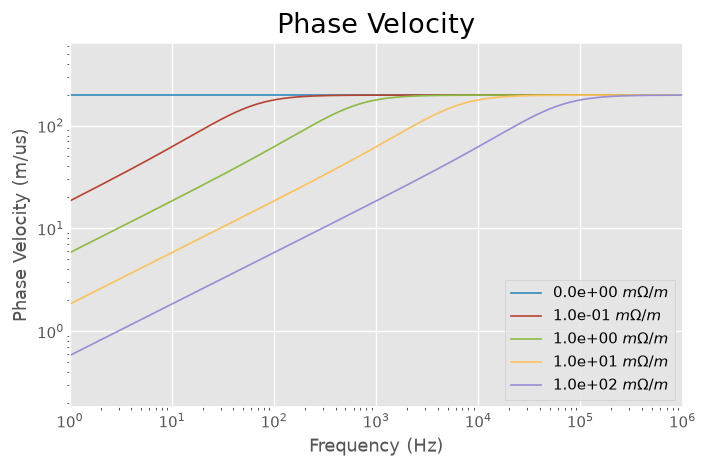

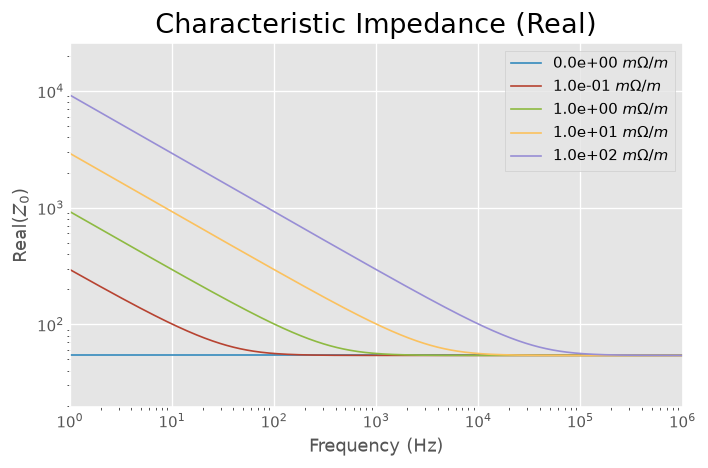

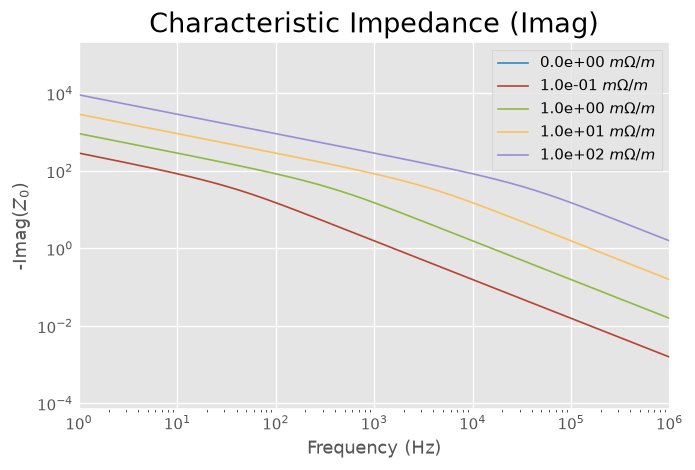

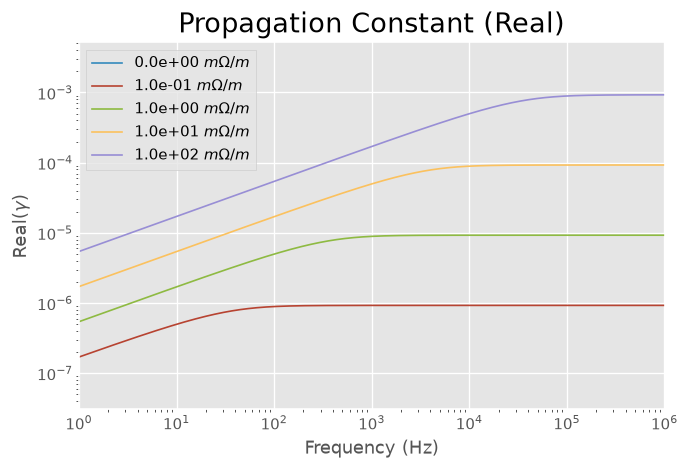

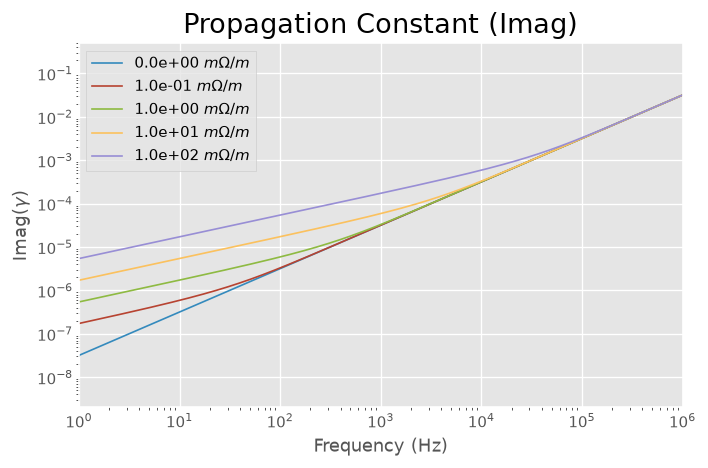

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import skrf as rf
from skrf.media import DistributedCircuit
from skrf.plotting import func_on_all_figs as foaf

%matplotlib inline

rf.stylely()



# define a frequency object from a vector
freq = rf.Frequency.from_f(np.logspace(0,6,1001), unit='hz')

# create a Media object for RG-58, based on distributed ckt values
rg58 = DistributedCircuit(
    frequency = freq,
    C =93.5e-12,#F/m
    L =273e-9,  #H/m
    R =0,#53e-3,   #Ohm/m
    G =0,       #S/m
    )


# loop thru values of resistivity plot various quantities
for k in (0,.1,1,10,100):
    rg58.R = k*1e-3

    plt.figure(0)
    plt.ylabel('Phase Velocity (m/us)')
    plt.title('Phase Velocity')
    plt.loglog(freq.f_scaled, rg58.v_p*1e-6, label=rf'{k:.1e} $m \Omega/m $')

    plt.figure(1)
    plt.ylabel('Real($Z_0$)')
    plt.title('Characteristic Impedance (Real)')
    plt.loglog(freq.f_scaled, rg58.z0.real, label=rf'{k:.1e} $m \Omega/m $')

    plt.figure(2)
    plt.ylabel('-Imag($Z_0$)')
    plt.title('Characteristic Impedance (Imag)')
    plt.plot(freq.f_scaled, -1*rg58.z0.imag, label=rf'{k:.1e} $m \Omega/m $')

    plt.figure(3)
    plt.ylabel(r'Real($\gamma$)')
    plt.title('Propagation Constant (Real)')
    plt.plot(freq.f_scaled, rg58.alpha, label=rf'{k:.1e} $m \Omega/m $')

    plt.figure(4)
    plt.ylabel(r'Imag($\gamma$)')
    plt.title('Propagation Constant (Imag)')
    plt.plot(freq.f_scaled, rg58.beta, label=rf'{k:.1e} $m \Omega/m $')





foaf(freq.labelXAxis)
foaf(plt.tight_layout)
foaf(plt.legend)
foaf(plt.loglog)

plt.tight_layout()
